In [4]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torch import nn

In [84]:
BATCH_SIZE=128
transform = transforms.Compose([
            transforms.ToTensor()
        ])
        
train_ds = datasets.CIFAR10(root="/tmp/data", train=True, download=True, transform=transform)
test_ds = datasets.CIFAR10(root="/tmp/data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)
x, y = next(iter(train_loader))

In [23]:
class MixUp():
    def __init__(self, loss_fn, alpha):
        self.alpha = alpha
        self.loss_fn = loss_fn
    def __call__(self, x, y):
        lam = torch.distributions.Beta(self.alpha, self.alpha).sample().item()        
        shuffled = torch.randperm(y.shape[0])
        x_mix = lam * x + (1-lam) * x[shuffled]
        return x_mix, y, y[shuffled], lam, shuffled
    def criterion(self, y, y_a, y_b, lam):
        return lam * self.loss_fn(y, y_a) + (1-lam) * self.loss_fn(y, y_b)

0.590539276599884


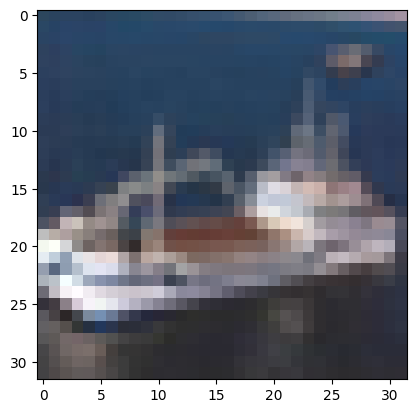

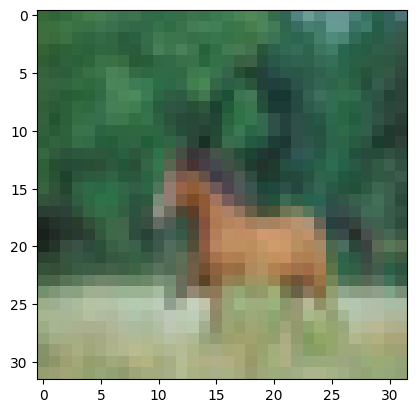

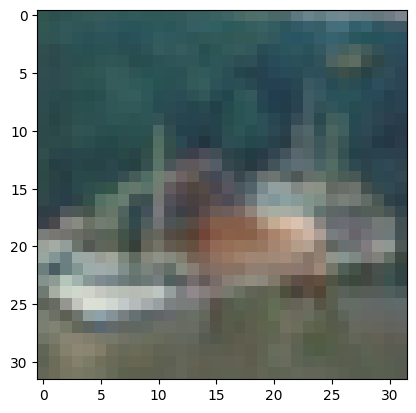

In [24]:

mixup = MixUp(nn.CrossEntropyLoss(), alpha=1.0)
x_mix, y_a, y_b, lam, shuffled = mixup(x, y)
print(lam)
# %%
import matplotlib.pyplot as plt
plt.imshow(x[0].permute(1,2,0).numpy())
plt.show()
plt.imshow(x[shuffled[0]].permute(1,2,0))
plt.show()
plt.imshow(x_mix[0].permute(1,2,0).numpy())
plt.show()

In [26]:
x.shape

torch.Size([128, 3, 32, 32])

In [114]:
import math
class CutMix():
    def __init__(self, loss_fn, alpha):
        self.alpha = alpha
        self.loss_fn = loss_fn

    def randbbox(self, lam, H, W):
        c_rat = math.sqrt(1 - lam)
        h = H * c_rat
        w = W * c_rat
        c_h = torch.randint(0, H, (1,)).item()
        c_w = torch.randint(0, W, (1,)).item()
        x1, x2 = max(c_h - h // 2, 0), min(c_h + h // 2, H)
        y1, y2 = max(c_w - w // 2, 0), min(c_w + w // 2, W)
        return int(x1), int(x2), int(y1), int(y2)

    def __call__(self, x, y):
        lam = torch.distributions.Beta(self.alpha, self.alpha).sample().item()
        B, H, W = x.shape[0], x.shape[2], x.shape[3]
        x1, x2, y1, y2 = self.randbbox(lam, H, W)
        shuffled = torch.randperm(B)
        x_cut = x.clone()
        x_cut[:, :, x1:x2, y1:y2] = x[shuffled, :, x1:x2, y1:y2]
        true_lam = (x2-x1)*(y2-y1) / (H * W)
        return x_cut, y, y[shuffled], true_lam, shuffled
    
    def criterion(self, y, y_a, y_b, lam):
        return lam * self.loss_fn(y, y_a) + (1-lam) * self.loss_fn(y, y_b)

0.431640625


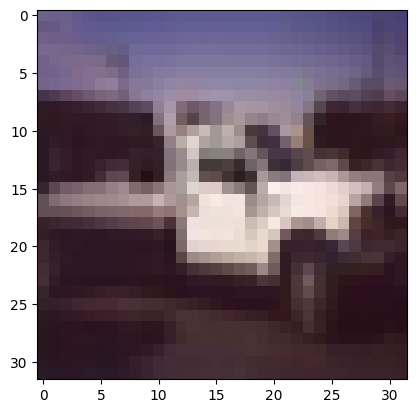

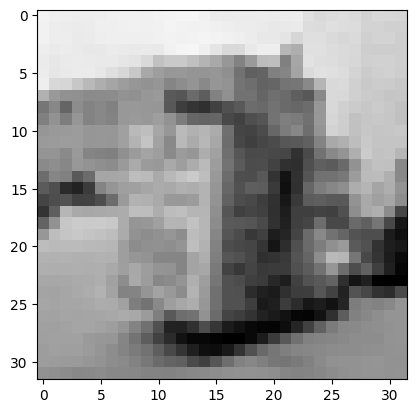

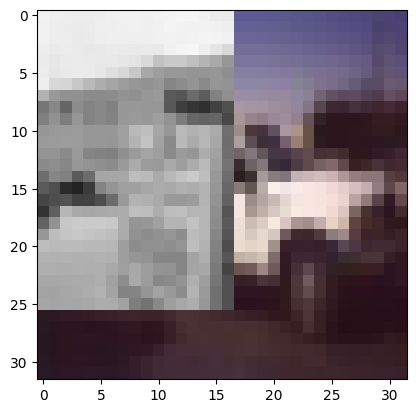

In [115]:
mixup = CutMix(loss_fn=nn.CrossEntropyLoss(), alpha=1.0)
x_mix, y_a, y_b, lam, shuffled = mixup(x, y)
print(lam)
# %%
import matplotlib.pyplot as plt
plt.imshow(x[1].permute(1,2,0).numpy())
plt.show()
plt.imshow(x[shuffled[1]].permute(1,2,0))
plt.show()
plt.imshow(x_mix[1].permute(1,2,0).numpy())
plt.show()

In [93]:
from torchvision.transforms import v2

In [99]:
cutmix = v2.CutMix(num_classes=10, alpha=1.0)

In [101]:
X, Y = cutmix(x, y)

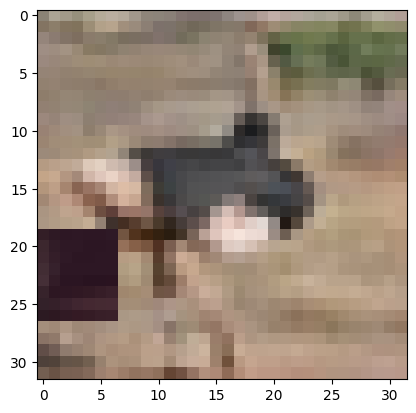

In [105]:
plt.imshow(X[2].permute(1,2,0).numpy())
plt.show()

In [107]:
Y[0]

tensor([0.9453, 0.0000, 0.0000, 0.0547, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000])